# Accuracy vs Cost Tradeoff — xRouteBench

Two views of the same 18-model candidate pool from `llmrouter_generic`
(train + test):

- **Chart 1 — Model vs Accuracy:** average task score per candidate.
- **Chart 2 — Model vs Cost:** average per-query dollar cost per candidate
  (from `llm_candidates` pricing × token usage).
- **Chart 3 — Cost vs Accuracy scatter (business case):** shows where the
  "cheap and good" models sit — the Pareto frontier a router exploits.

In [3]:
import sys
from pathlib import Path

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()),
    Path.cwd(),
)
sys.path.insert(0, str(ROOT))
from router.metrics import routing_aggregate

agg = routing_aggregate(splits=("train", "test"))
print(f"candidates={len(agg)}")
print(agg.sort_values("accuracy", ascending=False).to_string(index=False))

import matplotlib.pyplot as plt
import pandas as pd

# Router vs ground-truth oracle evaluation
from router.eval_router import router_vs_gt


candidates=18
                  model_name  accuracy  mean_cost  rows
            cogito-v2-1-671b  0.773521   0.000456  8218
                gpt-oss-120b  0.729319   0.000051  8218
llama-3.3-70b-instruct-turbo  0.727322   0.000258  8218
 qwen3-next-80b-a3b-instruct  0.724469   0.000423  8218
               deepseek-v3.1  0.694579   0.000287  8218
mistral-small-3-24b-instruct  0.692056   0.000057  8218
                 gpt-oss-20b  0.685632   0.000015  8218
            qwen3-coder-next  0.678319   0.000343  8218
            llama-4-maverick  0.672708   0.000312  8218
         llama3-70b-instruct  0.667704   0.000168  8218
               gemma-2-9b-it  0.652175   0.000022  8218
 mixtral-8x22b-instruct-v0.1  0.604403   0.000335  8218
         qwen2.5-7b-instruct  0.559621   0.000040  8218
   qwen2.5-7b-instruct-turbo  0.554545   0.000061  8218
    llama-3-8b-instruct-lite  0.527423   0.000018  8218
              rnj-1-instruct  0.488004   0.000048  8218
  mixtral-8x7b-instruct-v0.1  0.38

## Chart 1 — Model vs Accuracy

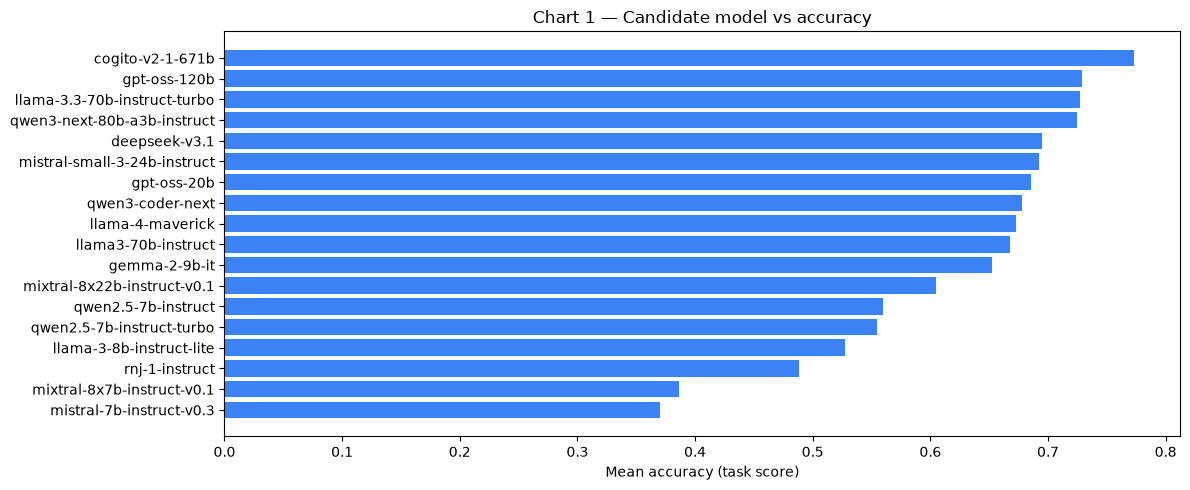

In [4]:
plt.figure(figsize=(12, 5))
by_acc = agg.sort_values("accuracy").reset_index(drop=True)
plt.barh(by_acc["model_name"], by_acc["accuracy"], color="#3b82f6")
plt.xlabel("Mean accuracy (task score)")
plt.title("Chart 1 — Candidate model vs accuracy")
plt.tight_layout()
plt.show()

## Chart 2 — Model vs Cost

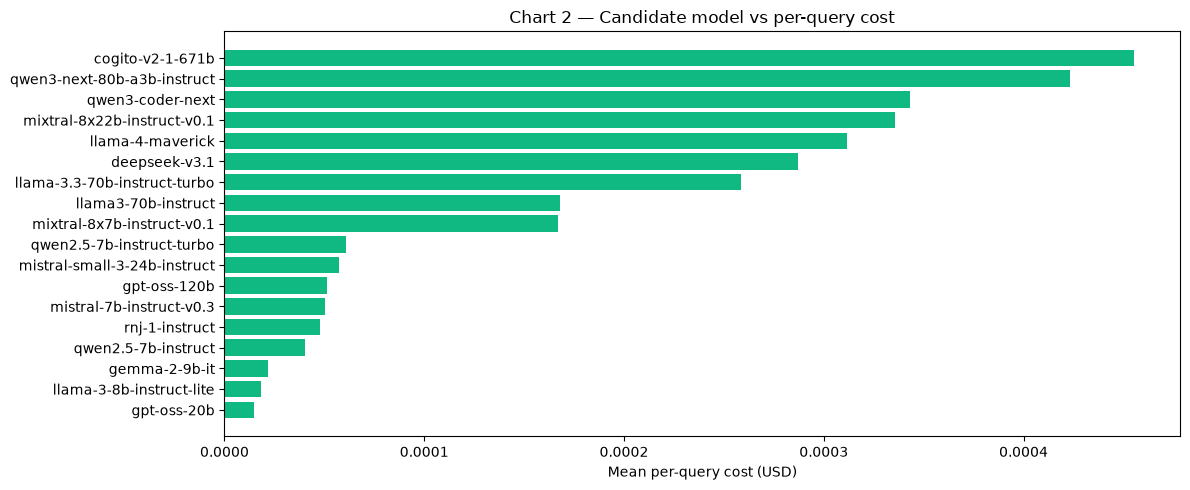

In [5]:
plt.figure(figsize=(12, 5))
by_cost = agg.sort_values("mean_cost").reset_index(drop=True)
plt.barh(by_cost["model_name"], by_cost["mean_cost"], color="#10b981")
plt.xlabel("Mean per-query cost (USD)")
plt.title("Chart 2 — Candidate model vs per-query cost")
plt.tight_layout()
plt.show()

## Chart 3 — Business case: cost vs accuracy tradeoff

Quadrants:
- **top-left = ideal** (high accuracy, low cost) → the models a router should use.
- bottom-right = expensive but not better (poor value).
The router wants to *pick on the Pareto frontier*: accuracy you need at the
lowest cost.

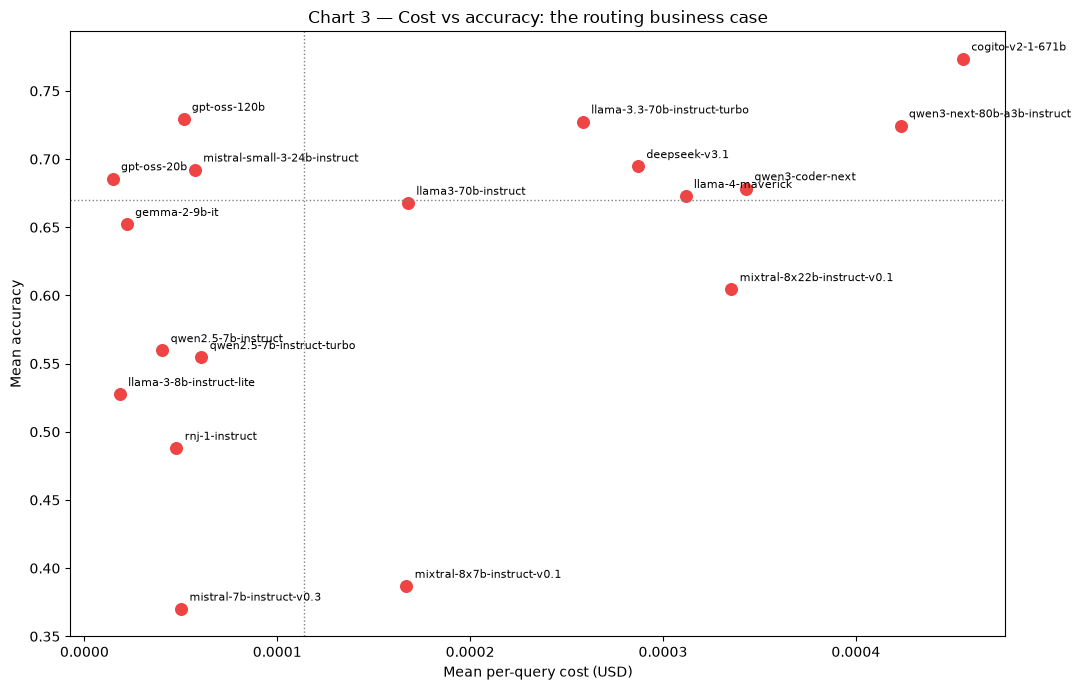

In [6]:
plt.figure(figsize=(11, 7))
plt.scatter(agg["mean_cost"], agg["accuracy"], s=70, color="#ef4444")
for _, r in agg.iterrows():
    plt.annotate(r["model_name"], (r["mean_cost"], r["accuracy"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.axvline(agg["mean_cost"].median(), color="gray", ls=":", lw=1)
plt.axhline(agg["accuracy"].median(), color="gray", ls=":", lw=1)
plt.xlabel("Mean per-query cost (USD)")
plt.ylabel("Mean accuracy")
plt.title("Chart 3 — Cost vs accuracy: the routing business case")
plt.tight_layout()
plt.show()


## Router vs Ground Truth Model (oracle)

We load the released System-1 router and compare its decisions against the
counterfactual oracle on the held-out test split. Metrics:
- **oracle_acc** — exact match with the oracle's cheapest-acceptable target.
- **acceptable_hit** — our pick lands within the ε-acceptable set.
- **realized cost / performance** — mean per-query US$ and task score actually
  delivered, vs what the oracle's picks would have delivered.


In [7]:

import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
sys.path.insert(0, str(ROOT))

RELEASE = ROOT / "training/router_releases/router_8ac97088cc"
print("loading release:", RELEASE)
gt = router_vs_gt(RELEASE)
print(f"oracle_acc={gt['oracle_acc']:.3f}  acceptable_hit={gt['acceptable_hit']:.3f}")
print(f"router cost=${gt['router_realized_cost']*1e6:.2f}e-6/query  perf={gt['router_realized_perf']:.3f}")
print(f"oracle cost=${gt['oracle_realized_cost']*1e6:.2f}e-6/query  perf={gt['oracle_realized_perf']:.3f}")


loading release: /home/mr/Desktop/Fireworks/training/router_releases/router_8ac97088cc


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 7341.74it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


oracle_acc=0.730  acceptable_hit=0.795
router cost=$11.95e-6/query  perf=0.717
oracle cost=$28.80e-6/query  perf=0.922



### Chart 4 — Decision fidelity: our router vs oracle & baseline


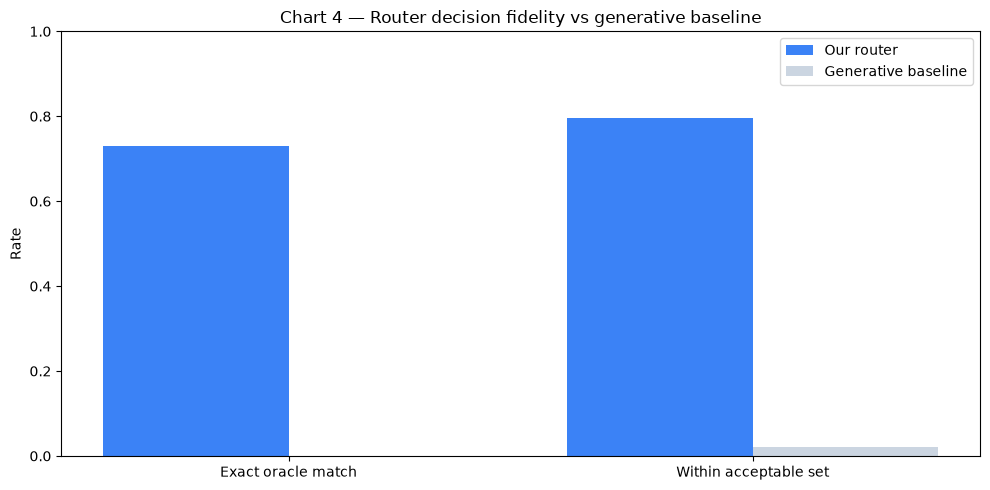

In [8]:

plt.figure(figsize=(10, 5))
labels = ["Exact oracle match", "Within acceptable set"]
our = [gt["oracle_acc"], gt["acceptable_hit"]]
base = [gt["gen_baseline"]["oracle_acc"], gt["gen_baseline"]["acceptable_hit"]]
x = range(len(labels))
plt.bar(x, our, width=0.4, label="Our router", color="#3b82f6")
plt.bar([i+0.4 for i in x], base, width=0.4, label="Generative baseline", color="#cbd5e1")
plt.xticks([i+0.2 for i in x], labels)
plt.ylim(0, 1)
plt.ylabel("Rate")
plt.title("Chart 4 — Router decision fidelity vs generative baseline")
plt.legend()
plt.tight_layout(); plt.show()



### Chart 5 — Realized cost vs performance (router vs oracle)


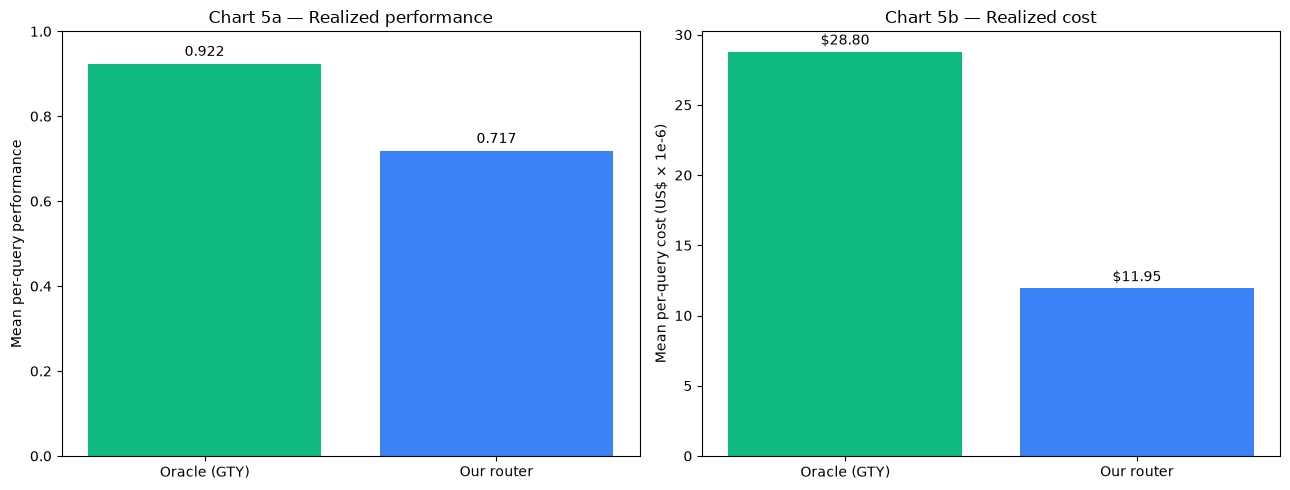

In [9]:

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
methods = ["Ground truth model", "Our router"]
perf = [gt["oracle_realized_perf"], gt["router_realized_perf"]]
cost = [gt["oracle_realized_cost"]*1e6, gt["router_realized_cost"]*1e6]
colors = ["#10b981", "#3b82f6"]

ax[0].bar(methods, perf, color=colors)
ax[0].set_ylabel("Mean per-query performance")
ax[0].set_title("Chart 5a — Realized performance")
ax[0].set_ylim(0, 1)
for i, v in enumerate(perf):
    ax[0].text(i, v + 0.02, f"{v:.3f}", ha="center")

ax[1].bar(methods, cost, color=colors)
ax[1].set_ylabel("Mean per-query cost (US$ × 1e-6)")
ax[1].set_title("Chart 5b — Realized cost")
for i, v in enumerate(cost):
    ax[1].text(i, v + 0.5, f"${v:.2f}", ha="center")
plt.tight_layout(); plt.show()



### Chart 6 — Router operating point on the cost-accuracy frontier


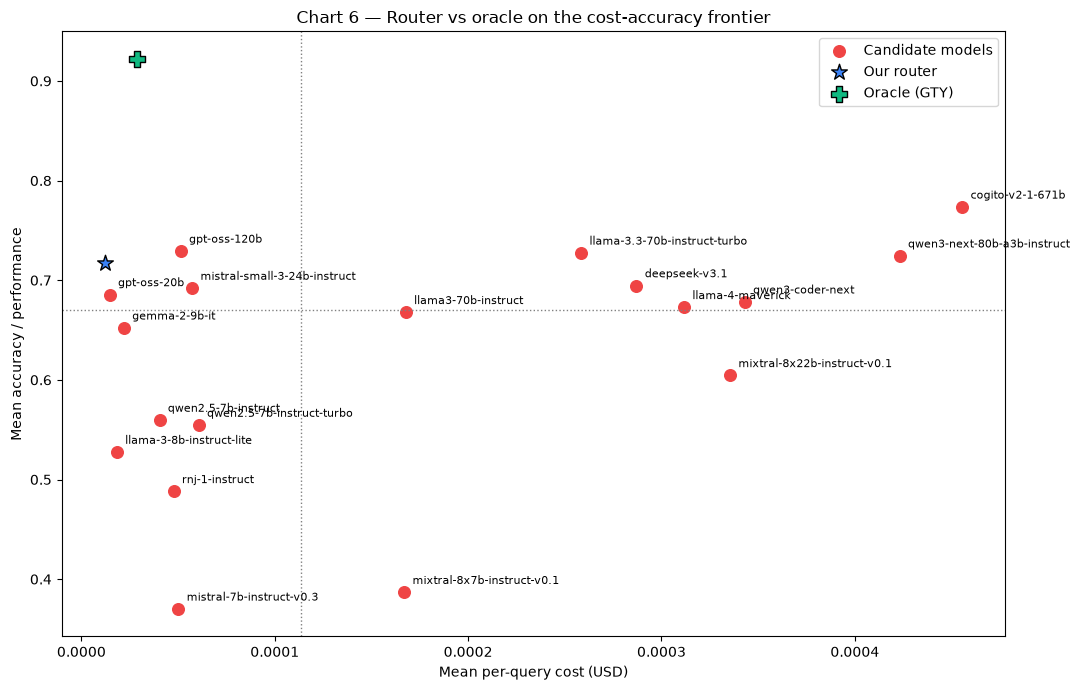

In [10]:

plt.figure(figsize=(11, 7))
plt.scatter(agg["mean_cost"], agg["accuracy"], s=70, color="#ef4444", label="Candidate models")
for _, r in agg.iterrows():
    plt.annotate(r["model_name"], (r["mean_cost"], r["accuracy"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.scatter([gt["router_realized_cost"]], [gt["router_realized_perf"]], s=140,
            marker="*", color="#3b82f6", edgecolors="black", zorder=5, label="Our router")
plt.scatter([gt["oracle_realized_cost"]], [gt["oracle_realized_perf"]], s=140,
            marker="P", color="#10b981", edgecolors="black", zorder=5, label="Ground truth model (oracle)")
plt.axvline(agg["mean_cost"].median(), color="gray", ls=":", lw=1)
plt.axhline(agg["accuracy"].median(), color="gray", ls=":", lw=1)
plt.xlabel("Mean per-query cost (USD)")
plt.ylabel("Mean accuracy / performance")
plt.title("Chart 6 — Router vs oracle on the cost-accuracy frontier")
plt.legend()
plt.tight_layout(); plt.show()
